# Final model comparison and paper figures

This notebook reproduces the frozen OTC medication challenge evaluation used in the ACM report. It **does not train or run inference with any model**. It reads saved outputs from Notebooks 06 and 07 and the archived Gemma experiment, applies the official version-3 scorer, checks every saved summary metric, and generates aggregate publication figures.

**Evaluation boundary.** The 230 cases are a selected, validation-derived challenge, not the original sealed test set. Its cases share medication families and use source-derived reference answers. The deterministic reference model is a source-consistency check, not independent clinical accuracy. The original sealed test is never read.

**Data policy.** Private case records and model outputs remain local. This notebook saves only aggregate tables, charts, and a manifest with file hashes. It does not export case IDs, private JSONL records, or model checkpoints.


## 1. Configure local paths

Run locally in the existing `otc-medication-llm-reliability` repository where possible. The notebook uses CPU only. If a folder is elsewhere, set the matching environment variable before running. The repository must contain the official `src/hrp` scoring code and the archived private files.

- `HRP_REPO_ROOT` points to the repository root.
- `HRP_GEMMA_ROOT` points to the folder containing `validated_outputs.PRIVATE.jsonl`.
- `HRP_SET_RUN_ROOT` points to the completed neural run folder containing `history.csv`.
- `HRP_NB08_OUTPUT_DIR` optionally selects the new aggregate-output folder.

The default search covers the HRP sibling folders in the original local project and the extracted Colab `data/hybrid_set_transformer_outputs` layout. Do not manually point the notebook to an earlier XGBoost run.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
import gzip
import hashlib
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
def find_repo_root():
    override = os.environ.get("HRP_REPO_ROOT")
    if override:
        root = Path(override).expanduser().resolve()
        if not (root / "src" / "hrp" / "challenge_scoring_v3.py").is_file():
            raise FileNotFoundError(f"HRP_REPO_ROOT does not point to the project: {root}")
        return root
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents, here / "otc-medication-llm-reliability"]:
        if (candidate / "src" / "hrp" / "challenge_scoring_v3.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Repository not located. Set HRP_REPO_ROOT to the existing project root."
    )

In [4]:
def choose_existing_folder(env_name, options, required_file):
    override = os.environ.get(env_name)
    candidates = [Path(override).expanduser()] if override else options
    for folder in candidates:
        if (folder / required_file).is_file():
            return folder.resolve()
    message = (f"Could not locate {required_file}. Set {env_name} to its folder. "
               f"Tried {len(candidates)} locations.")
    raise FileNotFoundError(message)

In [5]:
REPO_ROOT = find_repo_root()
HRP_ROOT = REPO_ROOT.parent
BENCHMARK = REPO_ROOT / "results" / "challenge_v1"
FINAL = (REPO_ROOT / "results" / "otc_models" /
         "xgboost_20261121T102526Z_4b76aa52" / "final_efdf93ed")
SET_FINAL = REPO_ROOT / "results" / "otc_models" / "set_transformer_final"
GEMMA = choose_existing_folder(
    "HRP_GEMMA_ROOT",
    [HRP_ROOT / "runpod-backups" / "stage06-audit" / "results" /
     "stage06_challenge_v1_original_gemma4",
     HRP_ROOT / "runpod-backups" / "stage06_challenge_v1_original_gemma4",
     REPO_ROOT / "runpod-backups" / "stage06_challenge_v1_original_gemma4"],
    "validated_outputs.PRIVATE.jsonl",
)
SET_RUN_NAME = "set_transformer_20261121T145558Z_63b2e44f"
SET_RUN = choose_existing_folder(
    "HRP_SET_RUN_ROOT",
    [HRP_ROOT / "hybrid_set_transformer_outputs" / SET_RUN_NAME,
     HRP_ROOT / "data" / "hybrid_set_transformer_outputs" / SET_RUN_NAME,
     REPO_ROOT / "hybrid_set_transformer_outputs" / SET_RUN_NAME],
    "history.csv",
)
OUTPUT_DIR = Path(os.environ.get(
    "HRP_NB08_OUTPUT_DIR", str(REPO_ROOT / "results" / "paper_figures_notebook08")
)).expanduser().resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
print("Repository ready:", REPO_ROOT.name)
print("Gemma archive located:", GEMMA.name)
print("Set Transformer run located:", SET_RUN.name)
print("New aggregate outputs:", OUTPUT_DIR)

Repository ready: otc-medication-llm-reliability
Gemma archive located: stage06_challenge_v1_original_gemma4
Set Transformer run located: set_transformer_20261121T145558Z_63b2e44f
New aggregate outputs: C:\Users\jibin\Documents\Academic\MSAI\8_AIH\HRP\otc-medication-llm-reliability\results\paper_figures_notebook08


## 2. Verify frozen files and import the scorer

The final scoring contract is `challenge_v1_scoring_contract_3`. It requires correct applicable formulations in the strict joint-accuracy calculation. Using the older contract would change the reported joint scores. All joins are made by case ID, not by record order.


In [7]:
REQUIRED = {
    "benchmark": BENCHMARK / "benchmark.PRIVATE.jsonl",
    "evidence": BENCHMARK / "common_evidence.PRIVATE.jsonl",
    "identities": BENCHMARK / "ingredient_identity_mapping.PRIVATE.jsonl",
    "deterministic": BENCHMARK / "deterministic_predictions.PRIVATE.jsonl",
    "archived_metrics": FINAL / "comparison_metrics.json",
    "archived_table": FINAL / "comparison.csv",
    "runtime": FINAL / "runtime.json",
    "xgboost": FINAL / "xgboost_predictions.jsonl.gz",
    "set_transformer": SET_FINAL / "set_transformer_predictions.jsonl.gz",
    "gemma": GEMMA / "validated_outputs.PRIVATE.jsonl",
    "set_history": SET_RUN / "history.csv",
    "scorer": REPO_ROOT / "src" / "hrp" / "challenge_scoring_v3.py",
}
missing = [name for name, path in REQUIRED.items() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing required archives: " + ", ".join(missing))

In [8]:
sys.path.insert(0, str(REPO_ROOT / "src"))

In [9]:
from hrp.challenge_evaluation import IdentityResolver
from hrp.challenge_scoring_v3 import (
    BENCHMARK_CONTRACT_VERSION,
    SCORING_CONTRACT_VERSION,
    score_predictions,
)

In [10]:
assert SCORING_CONTRACT_VERSION == "challenge_v1_scoring_contract_3"
assert BENCHMARK_CONTRACT_VERSION == "challenge_v1_contract_2"

In [11]:
def read_jsonl(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as stream:
        return [json.loads(line) for line in stream if line.strip()]

In [12]:
def unique_rows(rows, value_key, label):
    values = [row["case_id"] for row in rows]
    if len(values) != len(set(values)):
        raise AssertionError(f"Duplicate case IDs in {label}")
    return {row["case_id"]: row[value_key] for row in rows}

In [13]:
cases = read_jsonl(REQUIRED["benchmark"])
case_by_id = {case["case_id"]: case for case in cases}
assert len(cases) == len(case_by_id) == 230
assert all(case["partition"] == "validation" for case in cases)

In [14]:
payloads = unique_rows(read_jsonl(REQUIRED["evidence"]), "payload", "common evidence")
assert set(payloads) == set(case_by_id)
resolver = IdentityResolver(read_jsonl(REQUIRED["identities"]))

In [15]:
MODEL_FILES = {
    "XGBoost": (REQUIRED["xgboost"], "output"),
    "Hybrid Set Transformer": (REQUIRED["set_transformer"], "output"),
    "Original Gemma 4": (REQUIRED["gemma"], "output"),
    "Deterministic sources": (REQUIRED["deterministic"], "prediction"),
}
predictions = {
    name: unique_rows(read_jsonl(path), value_field, name)
    for name, (path, value_field) in MODEL_FILES.items()
}
for name, pred in predictions.items():
    assert set(pred).issubset(case_by_id)
    expected_n = 203 if name == "Original Gemma 4" else 230
    assert len(pred) == expected_n, (name, len(pred))


In [16]:
print("Frozen cases", len(cases))
print("Gemma accepted outputs", len(predictions["Original Gemma 4"]))
print("Invalid Gemma attempts retained in denominator", 230 - len(
    predictions["Original Gemma 4"]))
print("Frozen contract", SCORING_CONTRACT_VERSION)


Frozen cases 230
Gemma accepted outputs 203
Invalid Gemma attempts retained in denominator 27
Frozen contract challenge_v1_scoring_contract_3


## 3. Recalculate and cross-check the final comparison

Recompute all final metrics with the original scorer. The saved comparison file is used only as the expected result for an exact verification check. A mismatch stops execution rather than silently changing the published results.


In [17]:
model_order = ["XGBoost", "Hybrid Set Transformer", "Original Gemma 4", 
               "Deterministic sources"]
archived = json.loads(REQUIRED["archived_metrics"].read_text(encoding="utf-8"))
reports = {}

In [18]:
for name in model_order:
    report = score_predictions(cases, predictions[name], payloads, resolver)
    for scope in ("overall", "by_role", "by_category", "format_errors", "interpretation"):
        if report[scope] != archived[name][scope]:
            raise AssertionError(f"Scoring mismatch for {name}, {scope}")
    assert report["scoring_contract_version"] == SCORING_CONTRACT_VERSION
    reports[name] = report

In [19]:
EXPECTED_JOINT = {
    "XGBoost": 183,
    "Hybrid Set Transformer": 193,
    "Original Gemma 4": 194,
    "Deterministic sources": 230,
}

In [20]:
for name, count in EXPECTED_JOINT.items():
    assert reports[name]["overall"]["joint_case_accuracy"] == {
        "numerator": count, "denominator": 230, "value": count / 230
    }

expected_table = pd.read_csv(REQUIRED["archived_table"])
for row in expected_table.itertuples(index=False):
    observed = reports[row.model]["overall"][row.metric]
    assert observed["numerator"] == row.numerator
    assert observed["denominator"] == row.denominator
    assert np.isclose(observed["value"], row.value, rtol=0, atol=1e-14)

print("PASS: all overall, role, category, error and interpretation reports match")
print("PASS: comparison.csv matches the recalculated metrics")


PASS: all overall, role, category, error and interpretation reports match
PASS: comparison.csv matches the recalculated metrics


## 4. Final tables

The denominator is part of every reported metric. Joint accuracy and output validity count cases. Ingredient, NDC and formulation metrics count eligible product requests. Ingredient comparison counts supported two-product cases. The deterministic source resolver is displayed separately from the learned approaches because its answers and references share source policies.


In [21]:
METRIC_LABELS = {
    "joint_case_accuracy": "Joint case accuracy",
    "ingredient_set_accuracy": "Ingredient-set accuracy",
    "full_formulation_accuracy": "Full formulation accuracy",
    "unique_ndc_accuracy": "Unique NDC accuracy",
    "comparison_accuracy": "Ingredient comparison accuracy",
    "abstention_accuracy": "Correct ambiguity abstention",
    "valid_output_rate": "Valid structured output",
    "ingredient_precision": "Ingredient precision",
    "ingredient_recall": "Ingredient recall",
}

In [22]:
rows = []
for metric, label in METRIC_LABELS.items():
    row = {"Metric": label}
    for name in model_order:
        result = reports[name]["overall"][metric]
        row[name] = (f'{result["numerator"]}/{result["denominator"]} '
                     f'({100 * result["value"]:.2f}%)') if result["value"] is not None else "Not applicable"
    rows.append(row)
metrics_table = pd.DataFrame(rows)
metrics_table

,Metric,XGBoost,Hybrid Set Transformer,Original Gemma 4,Deterministic sources
0,Joint case accuracy,183/230 (79.57%),193/230 (83.91%),194/230 (84.35%),230/230 (100.00%)
1,Ingredient-set accuracy,369/409 (90.22%),373/409 (91.20%),400/409 (97.80%),409/409 (100.00%)
2,Full formulation accuracy,102/134 (76.12%),108/134 (80.60%),127/134 (94.78%),134/134 (100.00%)
3,Unique NDC accuracy,345/381 (90.55%),373/381 (97.90%),372/381 (97.64%),381/381 (100.00%)
4,Ingredient comparison accuracy,169/201 (84.08%),168/201 (83.58%),196/201 (97.51%),201/201 (100.00%)
5,Correct ambiguity abstention,22/22 (100.00%),22/22 (100.00%),0/22 (0.00%),22/22 (100.00%)
6,Valid structured output,230/230 (100.00%),230/230 (100.00%),203/230 (88.26%),230/230 (100.00%)
7,Ingredient precision,605/605 (100.00%),617/617 (100.00%),656/656 (100.00%),666/666 (100.00%)
8,Ingredient recall,605/666 (90.84%),617/666 (92.64%),656/666 (98.50%),666/666 (100.00%)


In [23]:
metrics_table.to_csv(OUTPUT_DIR / "model_comparison_table.csv", index=False)

In [24]:
ROLE_LABELS = {
    "different_without_ndc": "Different formulations, no NDC",
    "different_with_ndc": "Different formulations, with NDC",
    "same_ingredient_control": "Same-ingredient controls",
    "ambiguity": "Ambiguous descriptions",
    "supplementary": "Supplementary",
}
role_rows = []
for key, label in ROLE_LABELS.items():
    row = {"Role": label, "Cases": int(sum(c["scoring_role"] == key for c in cases))}
    for name in model_order:
        metric = reports[name]["by_role"][key]["joint_case_accuracy"]
        row[name + " correct"] = metric["numerator"]
        row[name + " percent"] = 100 * metric["value"]
    role_rows.append(row)
role_table = pd.DataFrame(role_rows)
assert role_table["Cases"].sum() == 230

In [25]:
role_table[["Role", "Cases", *[n+" correct" for n in model_order]]]


,Role,Cases,XGBoost correct,Hybrid Set Transformer correct,Original Gemma 4 correct,Deterministic sources correct
0,"Different formulations, no NDC",34,18,26,33,34
1,"Different formulations, with NDC",86,66,78,85,86
2,Same-ingredient controls,80,71,59,69,80
3,Ambiguous descriptions,22,22,22,0,22
4,Supplementary,8,6,8,7,8


In [26]:
role_table.to_csv(OUTPUT_DIR / "challenge_role_results.csv", index=False)

## 5. Publication charts

Figures are regenerated only from frozen summary results or the saved six-epoch training history. Each figure is saved as vector PDF for Overleaf and high-resolution PNG for preview. The archived source-coverage chart uses previously audited final-v5 counts rather than querying the raw FDA files again.


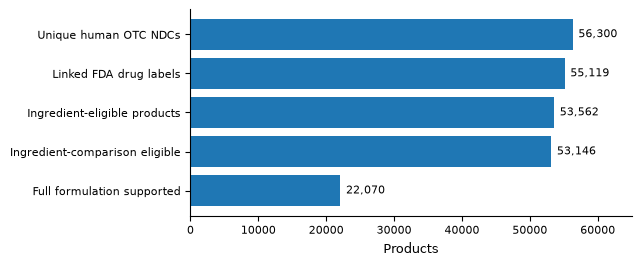

In [27]:
plt.rcParams.update({
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "savefig.dpi": 400,
})


def save_chart(fig, stem):
    for extension in ("pdf", "png"):
        fig.savefig(OUTPUT_DIR / f"{stem}.{extension}",
                    dpi=400, bbox_inches="tight")
    plt.show()
    plt.close(fig)


source_coverage = pd.DataFrame([
    {"Stage": "Unique human OTC NDCs", "Products": 56300},
    {"Stage": "Linked FDA drug labels", "Products": 55119},
    {"Stage": "Ingredient-eligible products", "Products": 53562},
    {"Stage": "Ingredient-comparison eligible", "Products": 53146},
    {"Stage": "Full formulation supported", "Products": 22070},
])

# Provenance - audited final_v5 source-eligibility summary, not a new data extraction.
source_coverage.to_csv(OUTPUT_DIR / "source_coverage_audited.csv", index=False)
fig, ax = plt.subplots(figsize=(6.3, 2.55), layout="constrained")
positions = np.arange(len(source_coverage))
ax.barh(positions, source_coverage["Products"])
ax.set_yticks(positions, source_coverage["Stage"])
ax.invert_yaxis()
ax.set_xlabel("Products")
ax.set_xlim(0, 65000)
for i, value in enumerate(source_coverage["Products"]):
    ax.text(value + 850, i, f"{value:,}", va="center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
save_chart(fig, "source_eligibility")


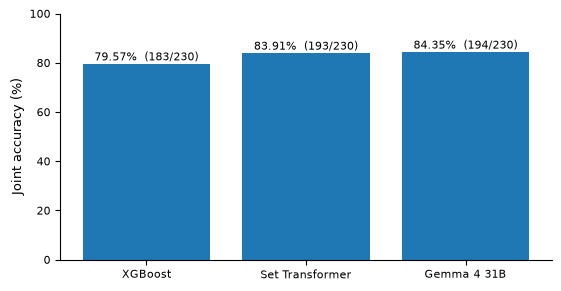

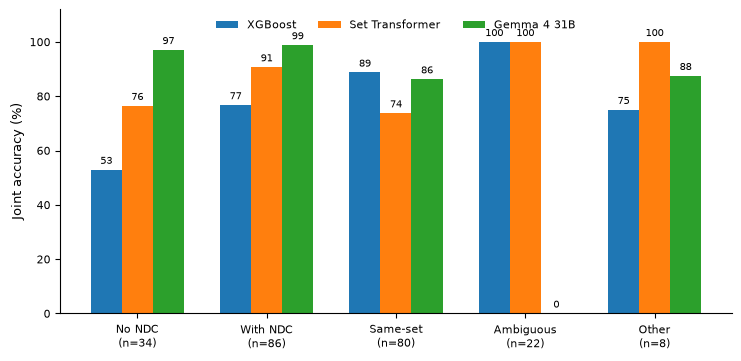

In [28]:
learned = model_order[:3]
name_short = {"XGBoost": "XGBoost", "Hybrid Set Transformer": "Set Transformer",
              "Original Gemma 4": "Gemma 4 31B"}
fig, ax = plt.subplots(figsize=(5.5, 2.8), layout="constrained")
values = [100 * reports[name]["overall"]["joint_case_accuracy"]["value"] for name in learned]
counts = [reports[name]["overall"]["joint_case_accuracy"]["numerator"] for name in learned]
ax.bar([name_short[name] for name in learned], values)
ax.set_ylim(0, 100)
ax.set_ylabel("Joint accuracy (%)")
for i, (value, count) in enumerate(zip(values, counts)):
    ax.text(i, value + 1.4, f"{value:.2f}%  ({count}/230)", ha="center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
save_chart(fig, "joint_accuracy")

fig, ax = plt.subplots(figsize=(7.3, 3.5), layout="constrained")
keys = list(ROLE_LABELS)
x = np.arange(len(keys))
width = 0.24
for j, name in enumerate(learned):
    vals = [100 * reports[name]["by_role"][key]["joint_case_accuracy"]["value"] for key in keys]
    bars = ax.bar(x + (j - 1) * width, vals, width, label=name_short[name])
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, val + 1.3,
                f"{val:.0f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x, ["No NDC\n(n=34)", "With NDC\n(n=86)", "Same-set\n(n=80)",
                  "Ambiguous\n(n=22)", "Other\n(n=8)"])
ax.set_ylim(0, 112)
ax.set_ylabel("Joint accuracy (%)")
ax.legend(ncol=3, frameon=False, loc="upper center")
ax.spines[["top", "right"]].set_visible(False)
save_chart(fig, "challenge_categories")


In [29]:
raw_guarded = []
for name in learned[:2]:
    before = archived[name]["raw_pipeline"]["overall"]["joint_case_accuracy"]
    after = reports[name]["overall"]["joint_case_accuracy"]
    raw_valid = archived[name]["raw_contract_validity"]
    after_valid = reports[name]["overall"]["valid_output_rate"]
    abstain_count = archived[name]["final_abstention"]
    false_abstain = archived[name]["final_false_abstention"]
    raw_guarded.append({
        "Model": name_short[name], "Before correct": before["numerator"],
        "After correct": after["numerator"], "Before %": 100 * before["value"],
        "After %": 100 * after["value"], "Raw valid": raw_valid["numerator"],
        "Final valid": after_valid["numerator"], "Correct abstentions": 22,
        "False abstentions": false_abstain["numerator"],
    })
raw_guarded_df = pd.DataFrame(raw_guarded)
assert raw_guarded_df["Before correct"].tolist() == [188, 172]
assert raw_guarded_df["After correct"].tolist() == [183, 193]
assert raw_guarded_df["False abstentions"].tolist() == [40, 36]

raw_guarded_df

,Model,Before correct,After correct,Before %,After %,Raw valid,Final valid,Correct abstentions,False abstentions
0,XGBoost,188,183,81.739130,79.565217,230,230,22,40
1,Set Transformer,172,193,74.782609,83.913043,184,230,22,36


In [30]:
raw_guarded_df.to_csv(OUTPUT_DIR / "verification_and_abstention.csv", index=False)

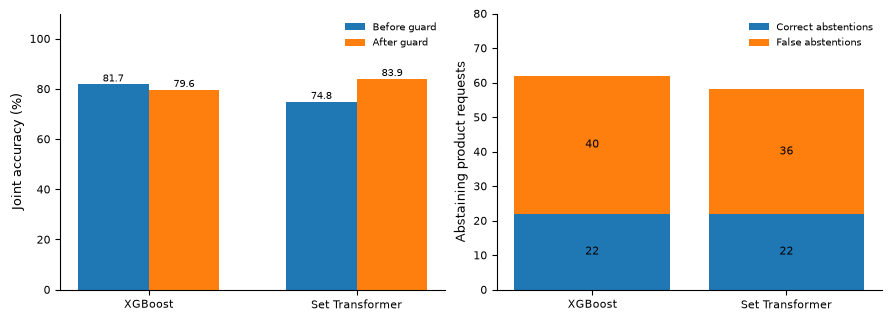

In [31]:
# Two separate visual panels with different units.
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.1), layout="constrained")
labels = raw_guarded_df["Model"].tolist()
x = np.arange(len(labels))
w = 0.34
axes[0].bar(x - w/2, raw_guarded_df["Before %"], w, label="Before guard")
axes[0].bar(x + w/2, raw_guarded_df["After %"], w, label="After guard")
axes[0].set_xticks(x, labels)
axes[0].set_ylim(0, 110)
axes[0].set_ylabel("Joint accuracy (%)")
axes[0].legend(frameon=False, fontsize=7)
for j, values in enumerate([raw_guarded_df["Before %"], raw_guarded_df["After %"]]):
    for i, value in enumerate(values):
        axes[0].text(i + (-w/2 if j == 0 else w/2), value + 1.2,
                     f"{value:.1f}", ha="center", fontsize=7)

axes[1].bar(x, raw_guarded_df["Correct abstentions"], label="Correct abstentions")
axes[1].bar(x, raw_guarded_df["False abstentions"],
            bottom=raw_guarded_df["Correct abstentions"], label="False abstentions")
axes[1].set_xticks(x, labels)
axes[1].set_ylabel("Abstaining product requests")
axes[1].set_ylim(0, 80)
axes[1].legend(frameon=False, fontsize=7)
for i, r in raw_guarded_df.iterrows():
    axes[1].text(i, r["Correct abstentions"]/2, str(int(r["Correct abstentions"])),
                 ha="center", va="center", fontsize=8)
    axes[1].text(i, r["Correct abstentions"] + r["False abstentions"]/2,
                 str(int(r["False abstentions"])), ha="center", va="center", fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
save_chart(fig, "verification_abstention")


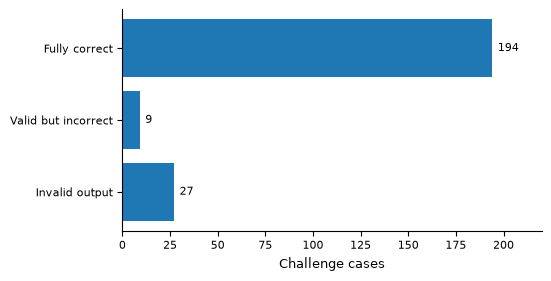

In [32]:
# A diagnostic breakdown of Gemma's strict output contract.
gemma_valid = reports["Original Gemma 4"]["overall"]["valid_output_rate"]["numerator"]
gemma_correct = reports["Original Gemma 4"]["overall"]["joint_case_accuracy"]["numerator"]
gemma_breakdown = pd.DataFrame([
    {"Outcome": "Fully correct", "Cases": gemma_correct},
    {"Outcome": "Valid but incorrect", "Cases": gemma_valid - gemma_correct},
    {"Outcome": "Invalid output", "Cases": 230 - gemma_valid},
])
assert gemma_breakdown["Cases"].tolist() == [194, 9, 27]
gemma_breakdown.to_csv(OUTPUT_DIR / "gemma_output_outcomes.csv", index=False)
fig, ax = plt.subplots(figsize=(5.4, 2.7), layout="constrained")
ax.barh(gemma_breakdown["Outcome"], gemma_breakdown["Cases"])
ax.invert_yaxis()
ax.set_xlim(0, 220)
ax.set_xlabel("Challenge cases")
for i, number in enumerate(gemma_breakdown["Cases"]):
    ax.text(number + 3, i, str(number), va="center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
save_chart(fig, "gemma_output_outcomes")


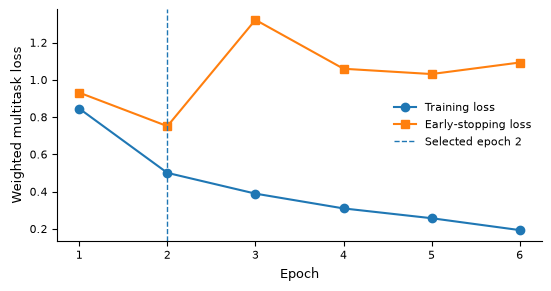

In [33]:
# Actual six-epoch run. The earlier three-epoch smoke curve is not used.
history = pd.read_csv(REQUIRED["set_history"])
assert history["epoch"].tolist() == [1, 2, 3, 4, 5, 6]
best_epoch = int(history.loc[history["stop_total_loss"].idxmin(), "epoch"])
assert best_epoch == 2
assert np.isclose(history["stop_total_loss"].min(), 0.7510674414633929)
fig, ax = plt.subplots(figsize=(5.4, 2.8), layout="constrained")
ax.plot(history["epoch"], history["train_total_loss"], "o-", label="Training loss")
ax.plot(history["epoch"], history["stop_total_loss"], "s-", label="Early-stopping loss")
ax.axvline(best_epoch, linestyle="--", linewidth=1.0, label="Selected epoch 2")
ax.set_xticks(history["epoch"])
ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted multitask loss")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_chart(fig, "full_training_curve")


In [34]:
runtime = json.loads(REQUIRED["runtime"].read_text(encoding="utf-8"))
resource_table = pd.DataFrame([
    {"Model": name_short[name], "Training min": round(runtime[name].get("training_seconds", 0) / 60, 2)
     if "training_seconds" in runtime[name] else "Not fine-tuned",
     "Inference seconds": runtime[name]["inference_seconds"],
     "Saved artifact MB": round(runtime[name]["model_bytes"] / 1e6, 2)
     if "model_bytes" in runtime[name] else "31B parameters",
     "Hardware": {"XGBoost": "CPU", "Hybrid Set Transformer": "T4 GPU",
                  "Original Gemma 4": "A100 GPU"}[name]}
    for name in learned
])
resource_table.to_csv(OUTPUT_DIR / "compute_observations.csv", index=False)
resource_table

,Model,Training min,Inference seconds,Saved artifact MB,Hardware
0,XGBoost,11.63,1.761983,10.79,CPU
1,Set Transformer,20.02,3.884192,3.55,T4 GPU
2,Gemma 4 31B,Not fine-tuned,10958.266122,31B parameters,A100 GPU


## 6. Optional paired family-clustered uncertainty analysis

This is an exploratory analysis of the frozen predictions. It does not change the original model results or establish statistical equivalence. If enabled, it uses case-level correctness under the same frozen scorer and resamples connected family components, rather than treating every derived product pair as independent. It adds descriptive uncertainty intervals but cannot establish statistical equivalence or replace a new external evaluation. It never changes the reported 183, 193 or 194 case counts.


In [35]:
RUN_CLUSTER_BOOTSTRAP = True
BOOTSTRAP_DRAWS = 2000

if RUN_CLUSTER_BOOTSTRAP:
    # One case can belong to two family groups. Join such groups into one component.
    parent = {}

    def find(x):
        parent.setdefault(x, x)
        if parent[x] != x:
            parent[x] = find(parent[x])
        return parent[x]

    def union(a, b):
        pa, pb = find(a), find(b)
        if pa != pb:
            parent[pb] = pa

    for case in cases:
        group_ids = case["families"]
        assert group_ids
        for f in group_ids[1:]:
            union(group_ids[0], f)

    # Per-case joint correctness is computed under the original amended scorer.
    correctness = {}
    for name in learned:
        correctness[name] = np.array([
            score_predictions(
                [case],
                ({case["case_id"]: predictions[name][case["case_id"]]}
                 if case["case_id"] in predictions[name] else {}),
                payloads, resolver,
            )["overall"]["joint_case_accuracy"]["numerator"]
            for case in cases
        ], dtype=np.int8)
        assert correctness[name].sum() == EXPECTED_JOINT[name]

    components = defaultdict(list)
    for index, case in enumerate(cases):
        components[find(case["families"][0])].append(index)
    group_indices = list(components.values())
    cluster_sizes = np.array([len(g) for g in group_indices])
    rng = np.random.default_rng(42)
    bootstrap_results = []

    for left, right in [("Hybrid Set Transformer", "Original Gemma 4"),
                        ("XGBoost", "Original Gemma 4")]:
        case_delta = correctness[left] - correctness[right]
        cluster_delta = np.array([case_delta[group].sum() for group in group_indices])
        draws = []
        for _ in range(BOOTSTRAP_DRAWS):
            selected = rng.integers(0, len(group_indices), size=len(group_indices))
            draws.append(100 * cluster_delta[selected].sum() / cluster_sizes[selected].sum())
        low, high = np.quantile(draws, [0.025, 0.975])
        bootstrap_results.append({
            "First model": left, "Second model": right,
            "Observed difference (pp)": 100 * case_delta.mean(),
            "Lower 95% (pp)": low, "Upper 95% (pp)": high,
            "Family components": len(group_indices),
        })
    bootstrap_df = pd.DataFrame(bootstrap_results)
    bootstrap_df.to_csv(OUTPUT_DIR / "exploratory_family_cluster_bootstrap.csv", index=False)
    display(bootstrap_df)
else:
    print("Optional family-clustered bootstrap was not run.")


,First model,Second model,Observed difference (pp),Lower 95% (pp),Upper 95% (pp),Family components
0,Hybrid Set Transformer,Original Gemma 4,-0.434783,-7.882097,6.667323,150
1,XGBoost,Original Gemma 4,-4.782609,-14.522927,4.933384,150


## 7. Save an aggregate-only reproducibility manifest

Save the output filenames and SHA-256 checksums used for this run. Only aggregate information is exported. Full benchmark references, model predictions, patient-level or product-level records, and private case IDs remain in their original directories.


In [36]:
def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "benchmark_contract": BENCHMARK_CONTRACT_VERSION,
    "scoring_contract": SCORING_CONTRACT_VERSION,
    "case_count": len(cases),
    "models": {name: {
        "joint_correct": reports[name]["overall"]["joint_case_accuracy"]["numerator"],
        "joint_total": 230,
        "valid_outputs": reports[name]["overall"]["valid_output_rate"]["numerator"],
    } for name in model_order},
    "input_file_sha256": {name: file_hash(path) for name, path in REQUIRED.items()},
    "publication_cautions": [
        "Selected validation-derived challenge, not original sealed test",
        "Source-derived references and deterministic policy are not independent clinical truth",
        "Gemma has 27 invalid attempts, retained as scoring failures",
        "Latency was measured on different hardware and pipelines",
        "Adapter contribution is not the same as learned-model capability",
    ],
    "aggregate_outputs": sorted(p.name for p in OUTPUT_DIR.glob("*.csv")) +
                         sorted(p.name for p in OUTPUT_DIR.glob("*.pdf")),
}
(OUTPUT_DIR / "notebook08_manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("PASS: frozen evaluation reproduced without training or model inference")
print("Publication charts generated:")
for file in sorted(OUTPUT_DIR.glob("*.pdf")):
    print(" ", file.name)
print("Aggregate tables saved:", len(list(OUTPUT_DIR.glob("*.csv"))))
print("No private case-level data exported.")


PASS: frozen evaluation reproduced without training or model inference
Publication charts generated:
  challenge_categories.pdf
  full_training_curve.pdf
  gemma_output_outcomes.pdf
  joint_accuracy.pdf
  source_eligibility.pdf
  verification_abstention.pdf
Aggregate tables saved: 7
No private case-level data exported.


## 8. Interpretation

The compact hybrid pipeline and Gemma differ by one case on joint accuracy, but Gemma remains stronger on ingredient set, full formulation and ingredient comparison accuracy. The final hybrid score depends substantially on deterministic postprocessing. Both compact pipelines correctly abstain on the 22 designated ambiguous requests, while also abstaining unnecessarily on answerable product requests. The perfect deterministic source resolver score should never be presented as independently verified clinical accuracy.

The exploratory bootstrap analysis is kept separate from the main model comparison and does not change the frozen accuracy results.